# Fundamentals of Data Science (22CSC59) — Case Studies 2 and 5

**Bolishetty Rahul · Roll No. 160124733167 · B.E. CSE, III Year, CBIT · Batch 2**

| Case study | Dataset | Techniques used |
|---|---|---|
| **2. Airline customer segmentation** | East-West Airlines frequent-flyer data (3,999 customers) | Data cleaning, outlier handling (Z-score / IQR), scaling, EDA, PCA, K-means (elbow + silhouette), hierarchical clustering (4 linkages), DBSCAN (eps × min_samples), silhouette and Davies–Bouldin evaluation |
| **5. Wine quality** | UCI Wine Quality — red wine (1,599 samples) | Descriptive statistics, coefficient of variation, Pearson correlation, histogram, box plot, heatmap, multiple linear regression, MAE / MSE / RMSE / R², multicollinearity (correlation matrix + VIF) |

Each code cell is preceded by its purpose and followed by the observations from its output. All figures are saved in `figures/`.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, rand_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
os.makedirs("figures", exist_ok=True)
def save(name):
    plt.savefig(f"figures/{name}.png"); plt.show()

---
# Part A — Case Study 2: Airline Customer Segmentation (Clustering)

**Problem:** East-West Airlines wants to learn more about its customers — their flying patterns, how they earn and use frequent-flyer rewards, and how they use the airline credit card. The task is to find **customer segments** using clustering.

Clustering is **unsupervised learning**: there is no target column. The algorithm groups customers so that customers in the same group are similar (small distance) and customers in different groups are different (large distance). We use **Euclidean distance**, so every feature must be on the same scale.

## A1. Load and understand the data

In [2]:
air_raw = pd.read_excel("data/EastWestAirlines.xlsx", sheet_name="data")
print("Shape:", air_raw.shape)
display(air_raw.head())
air_raw.info()

Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


*Observation:* 3,999 customers and 12 columns, all numeric. `ID#` only identifies a customer. `cc1_miles`, `cc2_miles` and `cc3_miles` are **bins**: 1 = under 5,000 miles, 2 = 5,000–10,000, 3 = 10,001–25,000, 4 = 25,001–50,000, 5 = over 50,000. `Award?` is 1 if the customer has redeemed an award.

## A2. Data preprocessing

### A2.1 Missing values and duplicates

In [3]:
print("Missing values in each column:")
print(air_raw.isnull().sum())
air = air_raw.drop(columns="ID#")                 # ID is not a customer behaviour
print("\nDuplicate rows (ignoring ID):", air.duplicated().sum())
air = air.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", air.shape)

Missing values in each column:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

Duplicate rows (ignoring ID): 1
Shape after removing duplicates: (3998, 11)


*Observation:* there are **no missing values**, so no filling (mean / median / mode) is needed. One duplicate customer profile was removed.

### A2.2 Columns with almost no variation

In [4]:
for c in ["cc1_miles", "cc2_miles", "cc3_miles"]:
    print(c, air[c].value_counts().sort_index().to_dict(), f"-> most common value = {air[c].value_counts(normalize=True).iloc[0]:.1%}")
air = air.drop(columns=["cc2_miles", "cc3_miles"])

cc1_miles {1: 2288, 2: 284, 3: 613, 4: 525, 5: 288} -> most common value = 57.2%
cc2_miles {1: 3955, 2: 28, 3: 15} -> most common value = 98.9%
cc3_miles {1: 3980, 2: 3, 3: 4, 4: 6, 5: 5} -> most common value = 99.5%


*Observation:* in `cc2_miles` (98.9%) and `cc3_miles` (99.5%) almost every customer has the value 1. A column that hardly changes cannot separate customers into groups, so both were dropped. `cc1_miles` varies and is kept.

### A2.3 Outlier detection and removal

Outliers are values far from the rest of the data. We check them with a **box plot**, then compare two rules:
- **IQR rule:** outlier if value < Q1 − 1.5·IQR or value > Q3 + 1.5·IQR.
- **Z-score rule:** z = (x − mean) / std; outlier if |z| > 3.

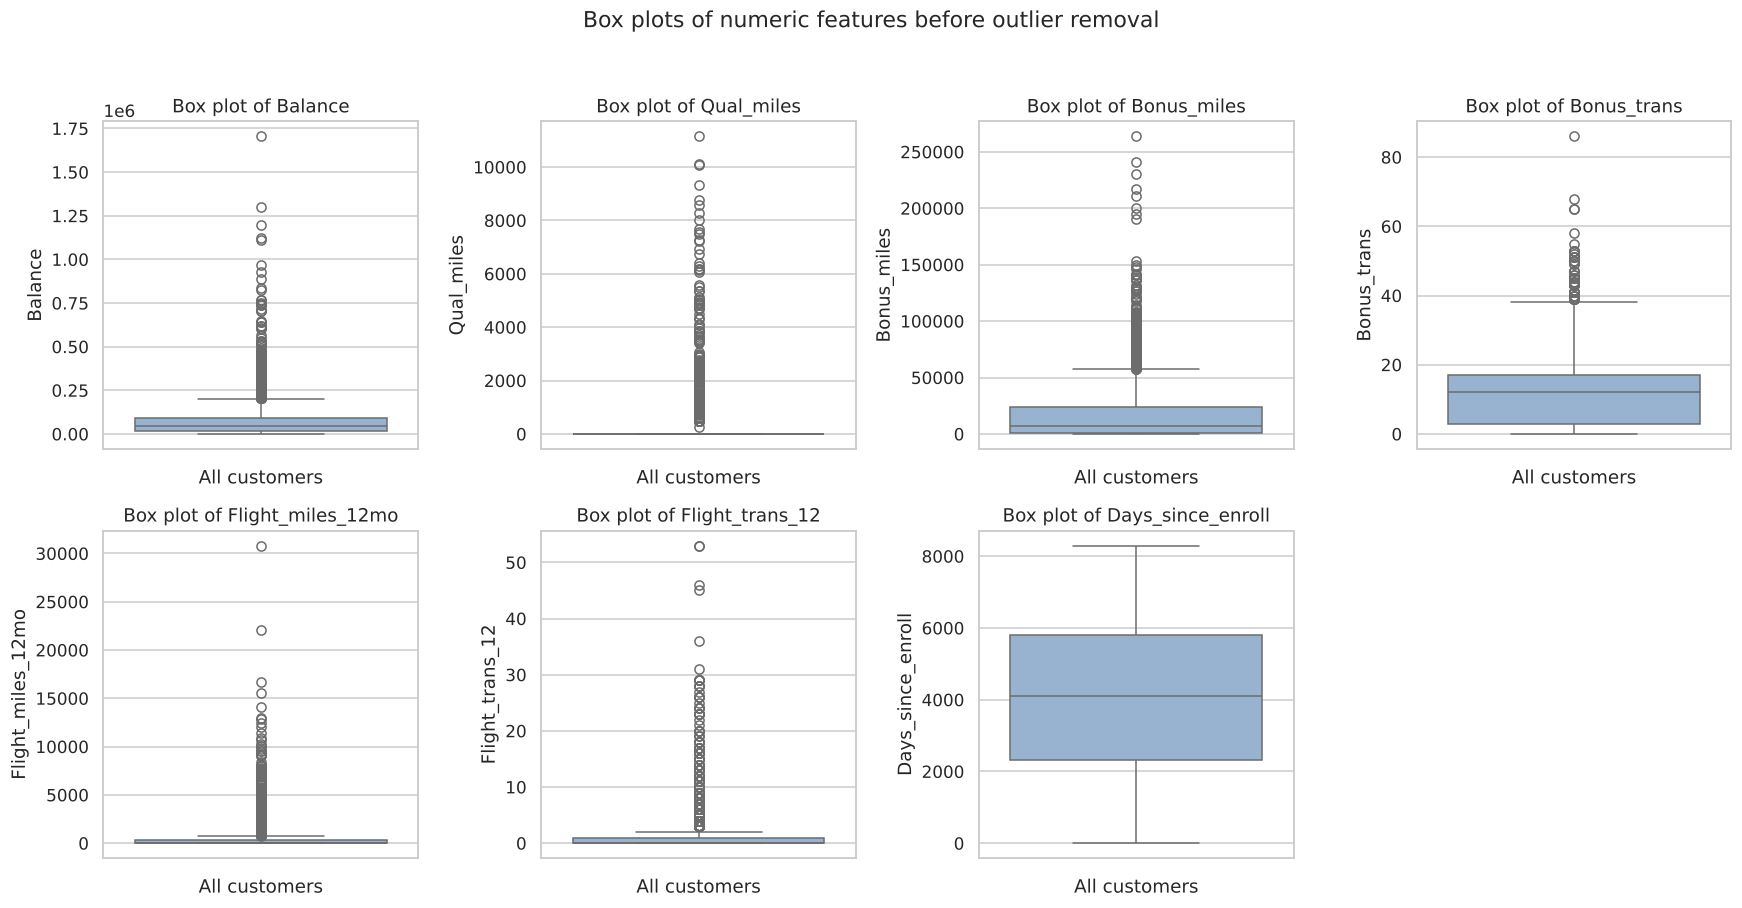

In [5]:
num_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12", "Days_since_enroll"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=air[c], ax=ax, color="#8fb3d9"); ax.set_title(f"Box plot of {c}"); ax.set_ylabel(c); ax.set_xlabel("All customers")
axes[1, 3].axis("off")
plt.suptitle("Box plots of numeric features before outlier removal", y=1.03); plt.tight_layout(); save("A_boxplots_before")

*Interpretation:* every mileage feature has many points above the upper whisker, i.e. a long tail of very large values. These extreme customers can pull the K-means centroids towards them, so outliers must be handled.

In [6]:
Q1, Q3 = air[num_cols].quantile(0.25), air[num_cols].quantile(0.75)
IQR = Q3 - Q1
iqr_outlier = ((air[num_cols] < Q1 - 1.5*IQR) | (air[num_cols] > Q3 + 1.5*IQR)).any(axis=1)

z = (air[num_cols] - air[num_cols].mean()) / air[num_cols].std()
z_outlier = (z.abs() > 3).any(axis=1)

print(f"IQR rule would remove    : {iqr_outlier.sum()} rows ({iqr_outlier.mean():.1%})")
print(f"Z-score rule (|z|>3) removes: {z_outlier.sum()} rows ({z_outlier.mean():.1%})")

air_clean = air[~z_outlier].reset_index(drop=True)
print("Customers after outlier removal:", len(air_clean))

IQR rule would remove    : 1089 rows (27.2%)
Z-score rule (|z|>3) removes: 321 rows (8.0%)
Customers after outlier removal: 3677


*Observation:* the IQR rule would delete **27%** of customers. For example, `Qual_miles` is zero for most customers, so Q1 = Q3 = 0 and *every* customer with qualifying miles becomes an "outlier"; the flight columns behave similarly. That would throw away the real active customers. The **Z-score rule (|z| > 3)** removes only the most extreme 8% of rows, so it was used.

### A2.4 Feature scaling

`Balance` is in lakhs of miles while `cc1_miles` is 1–5. Without scaling, `Balance` would dominate the Euclidean distance. **StandardScaler** converts every feature to mean 0 and standard deviation 1.

In [7]:
features = list(air_clean.columns)
X = StandardScaler().fit_transform(air_clean[features])
print("Features used for clustering:", features)
print("Shape of scaled data:", X.shape)
print("Mean of each scaled feature:", X.mean(axis=0).round(2))
print("Std of each scaled feature :", X.std(axis=0).round(2))

Features used for clustering: ['Balance', 'Qual_miles', 'cc1_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?']
Shape of scaled data: (3677, 9)
Mean of each scaled feature: [-0. -0. -0.  0. -0. -0.  0.  0.  0.]
Std of each scaled feature : [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## A3. Exploratory data analysis (EDA)

### A3.1 Descriptive statistics

In [8]:
desc = pd.DataFrame({"mean": air_clean[num_cols].mean(), "median": air_clean[num_cols].median(),
                     "mode": air_clean[num_cols].mode().iloc[0], "std": air_clean[num_cols].std(),
                     "skewness": air_clean[num_cols].skew(), "% zeros": 100*(air_clean[num_cols] == 0).mean()})
display(desc.round(2))

,mean,median,mode,std,skewness,% zeros
Balance,"60,536.320","39,372.000",1000,"61,875.440",1.890,0.030
Qual_miles,39.400,0.000,0,248.360,7.090,97.010
Bonus_miles,"14,415.740","6,000.000",0,"18,231.800",1.580,12.620
Bonus_trans,10.540,11.000,0,8.250,0.600,12.620
Flight_miles_12mo,256.690,0.000,0,637.160,3.550,72.120
Flight_trans_12,0.790,0.000,0,1.830,3.280,72.120
Days_since_enroll,"4,061.240","4,015.000",8296,"2,051.030",0.140,0.000


*Observation:* for Balance, Qual_miles, Bonus_miles and the flight columns the **mean is much larger than the median** and skewness is high (1.6–7.1) — most customers have small values and a few have very large ones (right-skewed). **97%** of customers have zero qualifying miles and **72%** took no flight in the last 12 months. Bonus_trans and Days_since_enroll are almost symmetric.

### A3.2 Univariate analysis — histograms and count plots

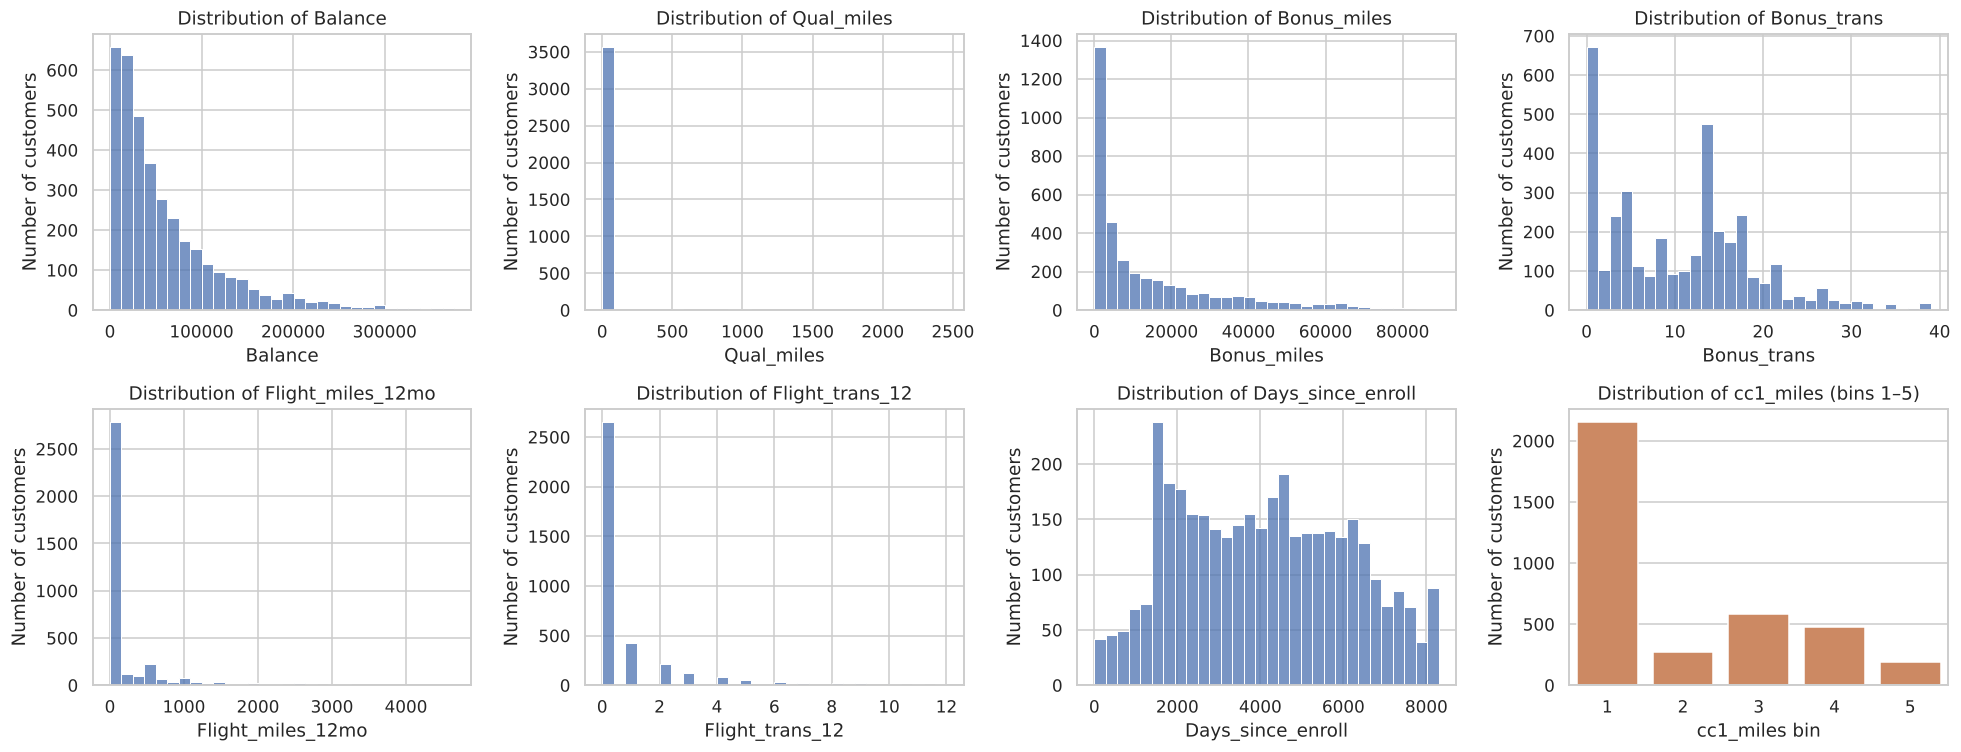

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(air_clean[c], bins=30, ax=ax, color="#4C72B0"); ax.set_title(f"Distribution of {c}"); ax.set_xlabel(c); ax.set_ylabel("Number of customers")
sns.countplot(x="cc1_miles", data=air_clean, ax=axes[1, 3], color="#DD8452"); axes[1, 3].set_title("Distribution of cc1_miles (bins 1–5)")
axes[1, 3].set_xlabel("cc1_miles bin"); axes[1, 3].set_ylabel("Number of customers")
plt.tight_layout(); save("A_histograms")

*Interpretation:* most histograms have a very tall bar near zero and a long tail to the right (right-skewed). Days_since_enroll is spread almost evenly. Most customers are in card bin 1 (under 5,000 miles).

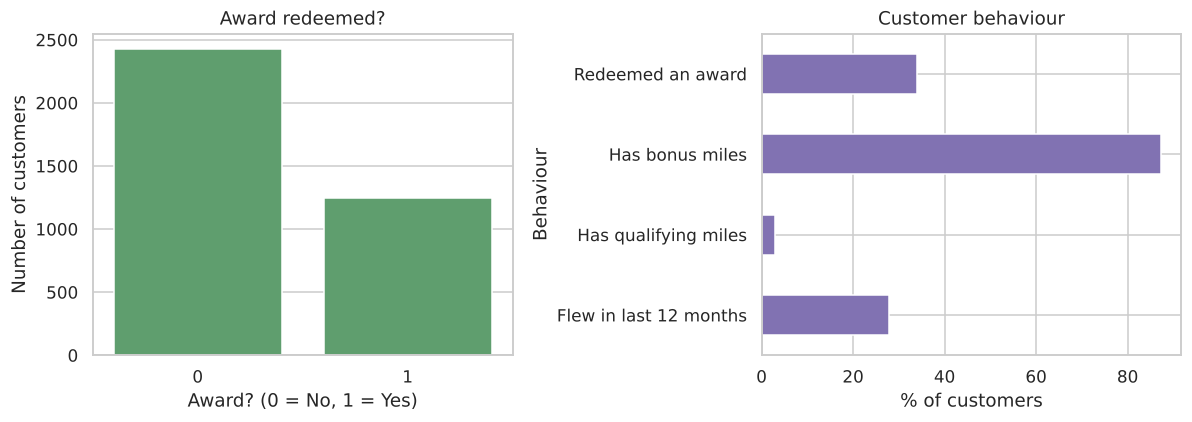

Flew in last 12 months   27.900
Has qualifying miles      3.000
Has bonus miles          87.400
Redeemed an award        34.000
dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Award?", data=air_clean, ax=axes[0], color="#55A868"); axes[0].set_title("Award redeemed?"); axes[0].set_xlabel("Award? (0 = No, 1 = Yes)"); axes[0].set_ylabel("Number of customers")
shares = pd.Series({"Flew in last 12 months": (air_clean.Flight_trans_12 > 0).mean(),
                    "Has qualifying miles": (air_clean.Qual_miles > 0).mean(),
                    "Has bonus miles": (air_clean.Bonus_miles > 0).mean(),
                    "Redeemed an award": air_clean["Award?"].mean()})
(shares*100).plot.barh(ax=axes[1], color="#8172B2"); axes[1].set_xlabel("% of customers"); axes[1].set_ylabel("Behaviour"); axes[1].set_title("Customer behaviour")
plt.tight_layout(); save("A_behaviour")
print((shares*100).round(1))

*Interpretation:* only about 28% of customers flew in the last 12 months and only 3% have qualifying miles, but about 87% earned bonus miles. So most customers earn miles without flying. About 34% have redeemed an award.

### A3.3 Bivariate analysis — scatter plots

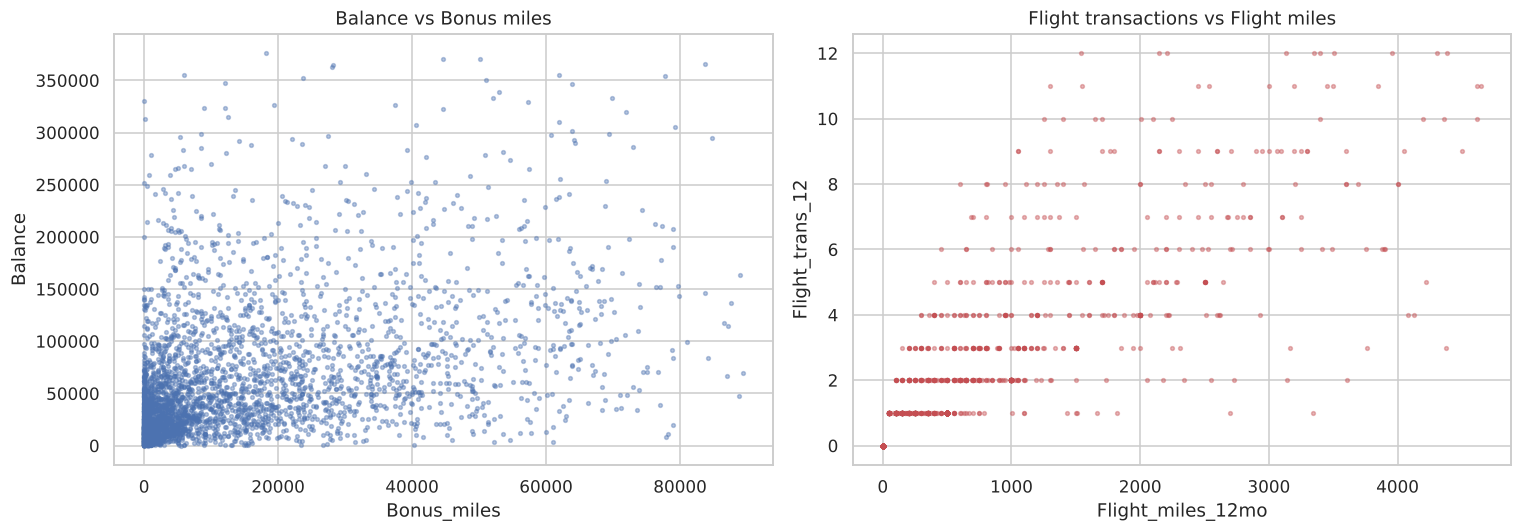

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(air_clean.Bonus_miles, air_clean.Balance, s=6, alpha=.4); axes[0].set_xlabel("Bonus_miles"); axes[0].set_ylabel("Balance"); axes[0].set_title("Balance vs Bonus miles")
axes[1].scatter(air_clean.Flight_miles_12mo, air_clean.Flight_trans_12, s=6, alpha=.4, color="#C44E52"); axes[1].set_xlabel("Flight_miles_12mo"); axes[1].set_ylabel("Flight_trans_12"); axes[1].set_title("Flight transactions vs Flight miles")
plt.tight_layout(); save("A_scatter")

*Interpretation:* balance increases with bonus miles, and flight transactions increase almost in a straight line with flight miles. Many points lie on the axes (zero bonus miles or zero flights).

### A3.4 Correlation heatmap

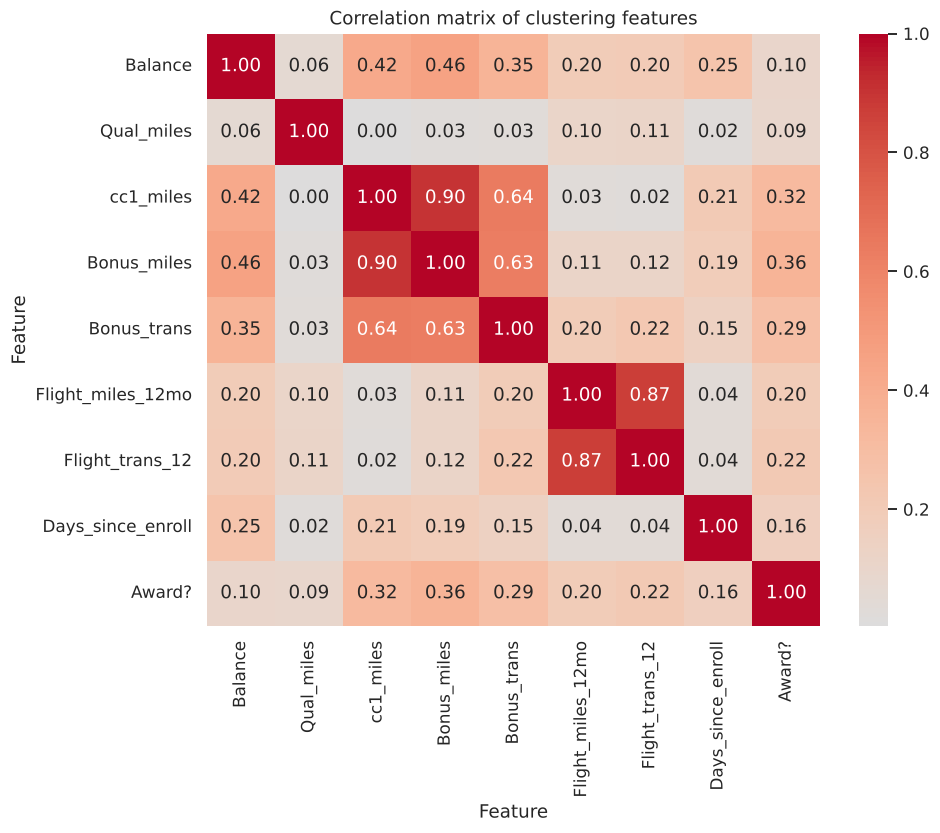

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(air_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix of clustering features"); plt.xlabel("Feature"); plt.ylabel("Feature"); save("A_corr_heatmap")

*Interpretation:* cc1_miles and Bonus_miles are strongly related (r = 0.90), and Flight_miles_12mo and Flight_trans_12 are strongly related (r = 0.87). The earning features and the flying features are only weakly related to each other, so *earning miles* and *flying* are two separate behaviours.

### A3.5 Multivariate analysis — pair plot

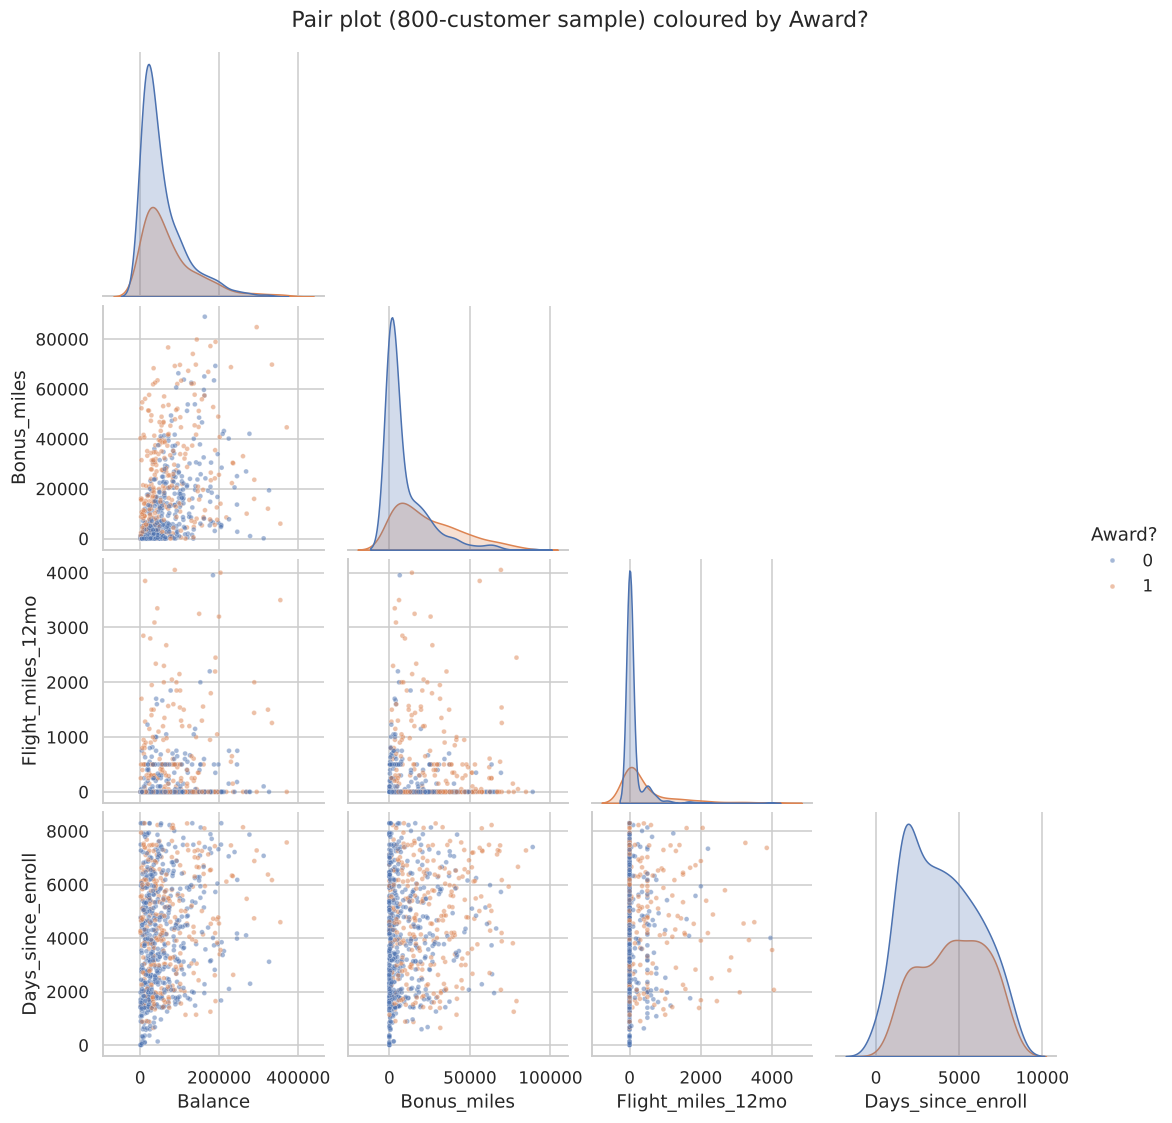

In [13]:
sample = air_clean.sample(800, random_state=RANDOM_STATE)
g = sns.pairplot(sample[["Balance", "Bonus_miles", "Flight_miles_12mo", "Days_since_enroll", "Award?"]], hue="Award?", plot_kws={"s": 10, "alpha": .5}, corner=True)
g.fig.suptitle("Pair plot (800-customer sample) coloured by Award?", y=1.02); save("A_pairplot")

*Interpretation:* customers who redeemed an award (Award? = 1) tend to have more bonus miles. Many points sit at zero flight miles, showing a large group of non-flying customers.

### A3.6 PCA for 2-D visualisation

Variance explained by PC1 and PC2: [0.351 0.202] -> total 0.552


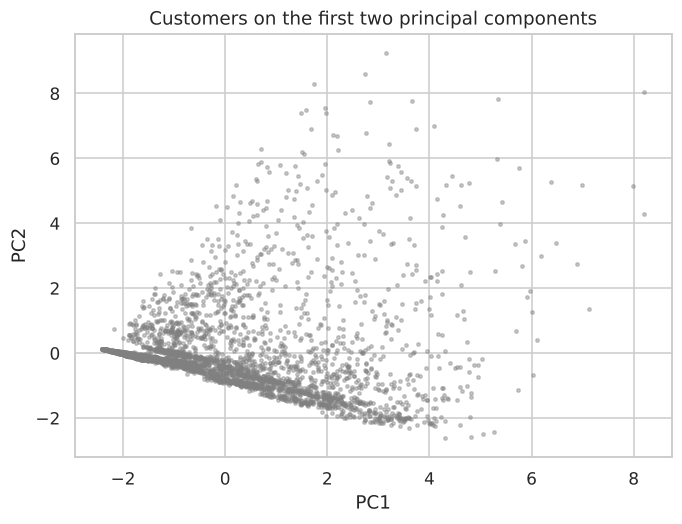

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3), "-> total", round(pca.explained_variance_ratio_.sum(), 3))
plt.figure(figsize=(7, 5)); plt.scatter(X_pca[:, 0], X_pca[:, 1], s=5, alpha=.4, color="grey")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Customers on the first two principal components"); save("A_pca")

*Interpretation:* PCA reduces the 9 features to 2 components **only for plotting** (PC1 ≈ 35% and PC2 ≈ 20% of the variance). The plot shows a dense band of low-activity customers and a spread-out cloud of active customers, not clearly separate round groups. All clustering below uses the full 9 scaled features.

## A4. K-means clustering

**Steps:** (1) choose k random centroids, (2) assign each customer to the nearest centroid, (3) recompute each centroid as the mean of its customers, (4) repeat until clusters stop changing.

**Choosing k:**
- **Elbow method** — plot WCSS (within-cluster sum of squares, `inertia_`) for k = 1 to 10 and look for the "elbow".
- **Silhouette method** — silhouette coefficient s = (b − a) / max(a, b), range −1 to 1; the k with the highest score is best.
- **Davies–Bouldin index** — lower is better.

,WCSS,silhouette,davies_bouldin
k,,,
2,"24,878.173",0.313,1.528
3,"20,317.824",0.318,1.301
4,"17,608.061",0.331,1.163
5,"15,726.761",0.276,1.262
6,"14,172.273",0.269,1.280
7,"12,999.927",0.238,1.259
8,"12,129.173",0.246,1.258
9,"11,494.661",0.250,1.254
10,"10,948.079",0.250,1.331


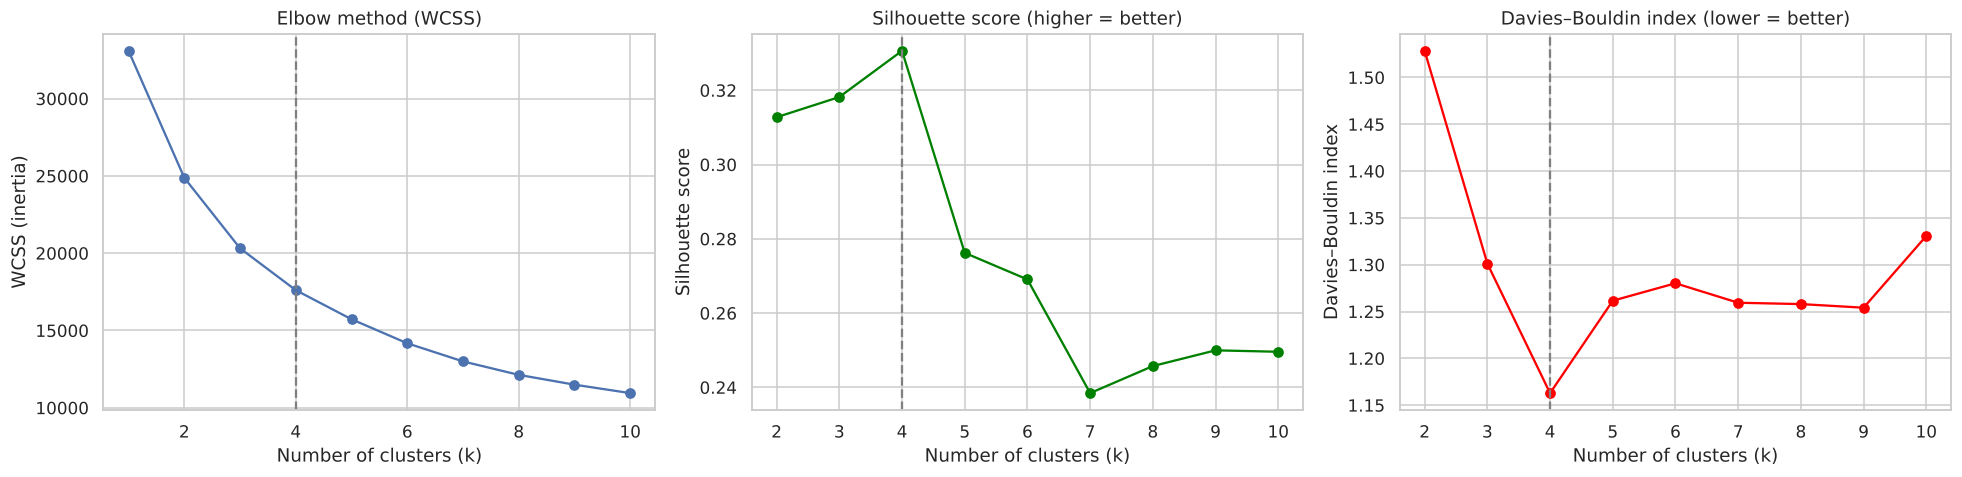

In [15]:
wcss = []
for k in range(1, 11):
    wcss.append(KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_)

rows = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    rows.append({"k": k, "WCSS": wcss[k-1], "silhouette": silhouette_score(X, labels), "davies_bouldin": davies_bouldin_score(X, labels)})
km_table = pd.DataFrame(rows).set_index("k"); display(km_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(range(1, 11), wcss, "o-"); axes[0].set_title("Elbow method (WCSS)")
axes[1].plot(km_table.index, km_table.silhouette, "o-", color="green"); axes[1].set_title("Silhouette score (higher = better)")
axes[2].plot(km_table.index, km_table.davies_bouldin, "o-", color="red"); axes[2].set_title("Davies–Bouldin index (lower = better)")
axes[0].set_ylabel("WCSS (inertia)"); axes[1].set_ylabel("Silhouette score"); axes[2].set_ylabel("Davies–Bouldin index")
for ax in axes: ax.set_xlabel("Number of clusters (k)"); ax.axvline(4, ls="--", color="grey")
plt.tight_layout(); save("A_kmeans_elbow")

*Observation:* the WCSS curve drops quickly up to k = 4 and then flattens (the elbow), the silhouette score is highest at **k = 4 (0.331)**, and the Davies–Bouldin index is lowest at **k = 4 (1.163)**. All three methods agree, so **k = 4** was chosen.

In [16]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X)
print("Customers in each cluster:", np.bincount(km_labels))
print("Silhouette score    :", round(silhouette_score(X, km_labels), 3))
print("Davies–Bouldin index:", round(davies_bouldin_score(X, km_labels), 3))

Customers in each cluster: [ 241 2174 1190   72]
Silhouette score    : 0.331
Davies–Bouldin index: 1.163


## A5. Hierarchical (agglomerative) clustering

Agglomerative clustering is **bottom-up**: every customer starts as its own cluster, and the two closest clusters are merged again and again. The merge history is drawn as a **dendrogram**. The **linkage** decides how distance between two clusters is measured:

| Linkage | Distance between clusters |
|---|---|
| Single | closest pair of points |
| Complete | farthest pair of points |
| Average | average of all pairwise distances |
| Ward | increase in within-cluster variance after merging |

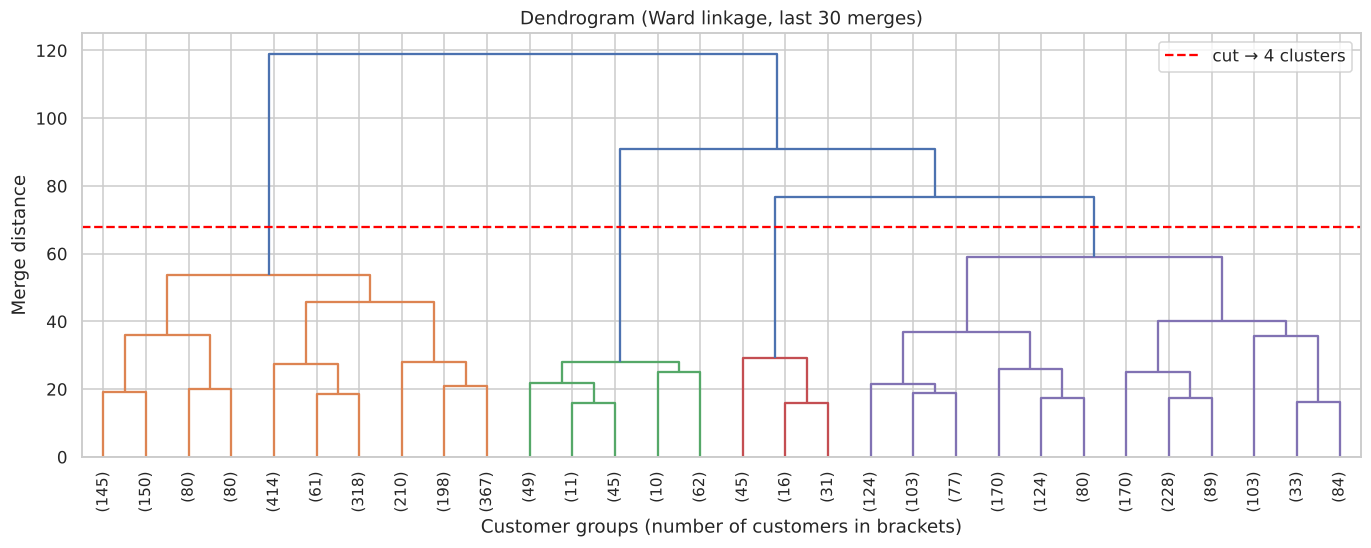

In [17]:
Z = linkage(X, method="ward")
cut = (Z[-4, 2] + Z[-3, 2]) / 2          # height that gives 4 clusters
plt.figure(figsize=(15, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, color_threshold=cut)
plt.axhline(cut, color="red", ls="--", label="cut → 4 clusters"); plt.legend()
plt.title("Dendrogram (Ward linkage, last 30 merges)"); plt.xlabel("Customer groups (number of customers in brackets)"); plt.ylabel("Merge distance"); save("A_dendrogram")

*Interpretation:* the last three merges happen at much larger distances than all earlier merges, which means there are a few large, well-separated groups. Cutting the tree at the red line gives 4 clusters.

,linkage,k,silhouette,davies_bouldin,cluster sizes
0,single,2,0.717,0.198,"[3676, 1]"
1,single,3,0.651,0.331,"[3674, 2, 1]"
2,single,4,0.464,0.356,"[3673, 2, 1, 1]"
3,single,5,0.463,0.347,"[3672, 2, 1, 1, 1]"
4,complete,2,0.506,1.106,"[3583, 94]"
5,complete,3,0.483,1.041,"[3583, 85, 9]"
6,complete,4,0.479,1.097,"[3478, 105, 85, 9]"
7,complete,5,0.216,1.455,"[3243, 235, 105, 85, 9]"
8,average,2,0.580,0.931,"[3617, 60]"
9,average,3,0.559,0.919,"[3617, 48, 12]"


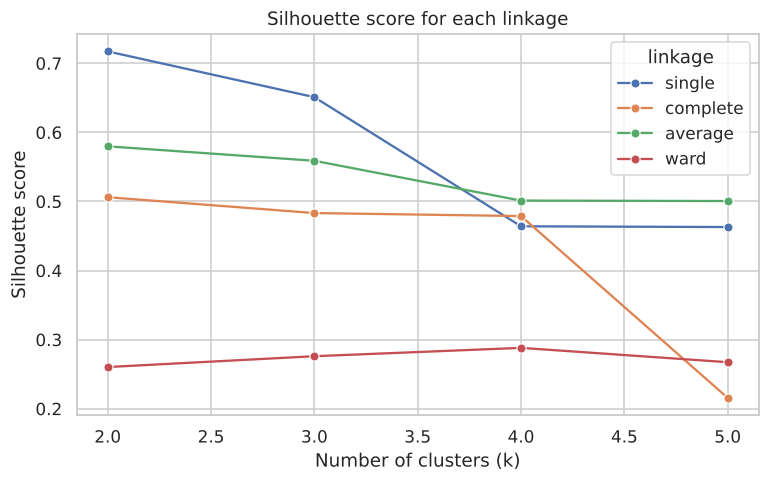

In [18]:
rows = []
for link in ["single", "complete", "average", "ward"]:
    for k in [2, 3, 4, 5]:
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X)
        rows.append({"linkage": link, "k": k, "silhouette": silhouette_score(X, labels),
                     "davies_bouldin": davies_bouldin_score(X, labels), "cluster sizes": sorted(np.bincount(labels).tolist(), reverse=True)})
hc_table = pd.DataFrame(rows); display(hc_table)

plt.figure(figsize=(8, 4.5))
sns.lineplot(data=hc_table, x="k", y="silhouette", hue="linkage", marker="o")
plt.title("Silhouette score for each linkage"); plt.xlabel("Number of clusters (k)"); plt.ylabel("Silhouette score"); save("A_hier_linkage")

*Observation:* single, complete and average linkage get **high silhouette scores, but look at the cluster sizes** — almost all customers fall into one giant cluster and the other "clusters" contain only a handful of extreme customers. Single linkage is the worst (chaining). Such a split is useless for marketing. **Ward linkage** gives balanced clusters with a reasonable silhouette, so **Ward with k = 4** was selected. A high silhouette alone does not guarantee useful clusters — cluster sizes must also be checked.

In [19]:
hc_labels = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X)
print("Customers in each cluster:", np.bincount(hc_labels))
print("Silhouette score    :", round(silhouette_score(X, hc_labels), 3))
print("Davies–Bouldin index:", round(davies_bouldin_score(X, hc_labels), 3))

Customers in each cluster: [1385 2023  177   92]
Silhouette score    : 0.288
Davies–Bouldin index: 1.251


## A6. DBSCAN clustering

DBSCAN groups points that lie in **dense** regions and marks isolated points as **noise (label −1)**. It does not need k, but needs two parameters:
- `eps` — radius of the neighbourhood around a point.
- `min_samples` (minPts) — minimum number of points inside `eps` to form a dense region.

We try several combinations and record the number of clusters, the noise percentage and the silhouette score (computed on non-noise points).

,min_samples,eps,clusters,noise_%,silhouette
0,5,0.600,21,36.307,0.043
1,5,0.800,13,23.497,0.146
2,5,1.000,3,15.828,0.268
3,5,1.200,5,11.368,0.246
4,5,1.400,3,8.023,0.263
5,10,0.600,10,44.955,0.174
6,10,0.800,4,29.888,0.274
7,10,1.000,2,19.772,0.301
8,10,1.200,2,13.952,0.284
9,10,1.400,2,10.307,0.276


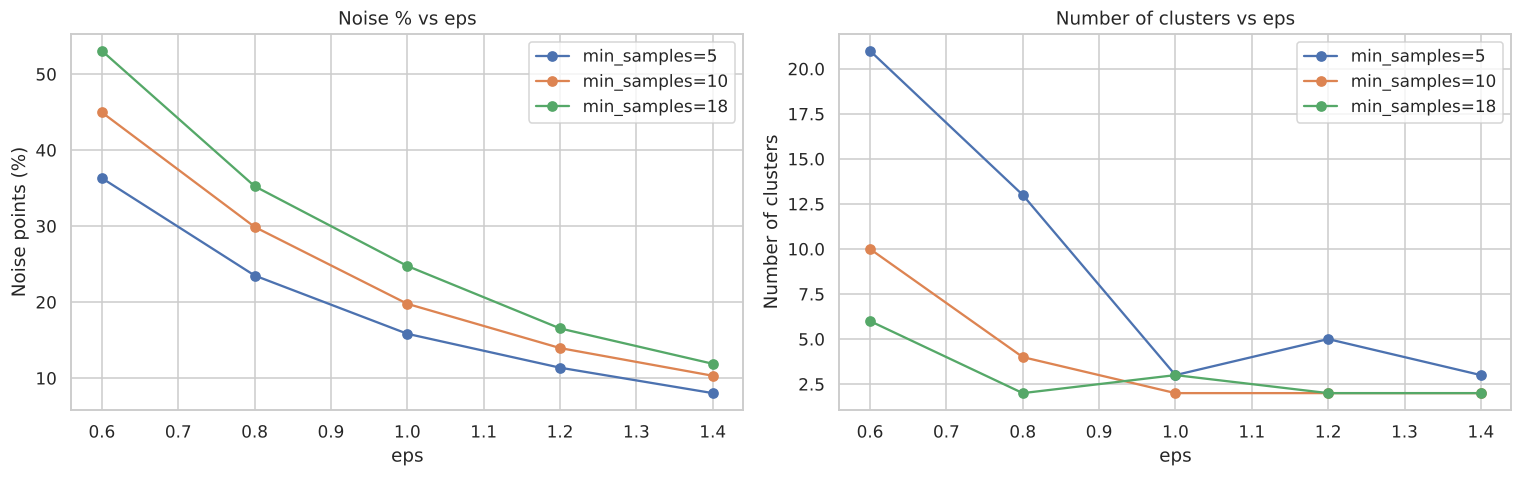

In [20]:
rows = []
for ms in [5, 10, 18]:
    for eps in [0.6, 0.8, 1.0, 1.2, 1.4]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        mask = labels != -1
        sil = silhouette_score(X[mask], labels[mask]) if n_clusters > 1 else np.nan
        rows.append({"min_samples": ms, "eps": eps, "clusters": n_clusters, "noise_%": 100*(~mask).mean(), "silhouette": sil})
db_table = pd.DataFrame(rows); display(db_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ms in [5, 10, 18]:
    t = db_table[db_table.min_samples == ms]
    axes[0].plot(t.eps, t["noise_%"], "o-", label=f"min_samples={ms}")
    axes[1].plot(t.eps, t["clusters"], "o-", label=f"min_samples={ms}")
axes[0].set_title("Noise % vs eps"); axes[1].set_title("Number of clusters vs eps")
axes[0].set_ylabel("Noise points (%)"); axes[1].set_ylabel("Number of clusters")
for ax in axes: ax.set_xlabel("eps"); ax.legend()
plt.tight_layout(); save("A_dbscan_params")

*Observation:* a **small eps** marks a large part of the data as noise and creates many tiny clusters; a **large eps** reduces noise but merges customers into only two big groups. A larger `min_samples` increases noise. We pick the setting with the **highest silhouette among those with at most 20% noise and at least 2 clusters**.

In [21]:
ok = db_table[(db_table["noise_%"] <= 20) & (db_table.clusters >= 2)]
best = ok.sort_values("silhouette", ascending=False).iloc[0]
print("Chosen parameters:", dict(eps=best.eps, min_samples=int(best.min_samples)))
db_labels = DBSCAN(eps=best.eps, min_samples=int(best.min_samples)).fit_predict(X)
print("Cluster sizes (-1 = noise):", pd.Series(db_labels).value_counts().sort_index().to_dict())
mask = db_labels != -1
print("Silhouette (without noise):", round(silhouette_score(X[mask], db_labels[mask]), 3))
print("Davies–Bouldin (without noise):", round(davies_bouldin_score(X[mask], db_labels[mask]), 3))

Chosen parameters: {'eps': np.float64(1.0), 'min_samples': 10}
Cluster sizes (-1 = noise): {-1: 727, 0: 2131, 1: 819}
Silhouette (without noise): 0.301
Davies–Bouldin (without noise): 1.534


## A7. Visualising the clusters

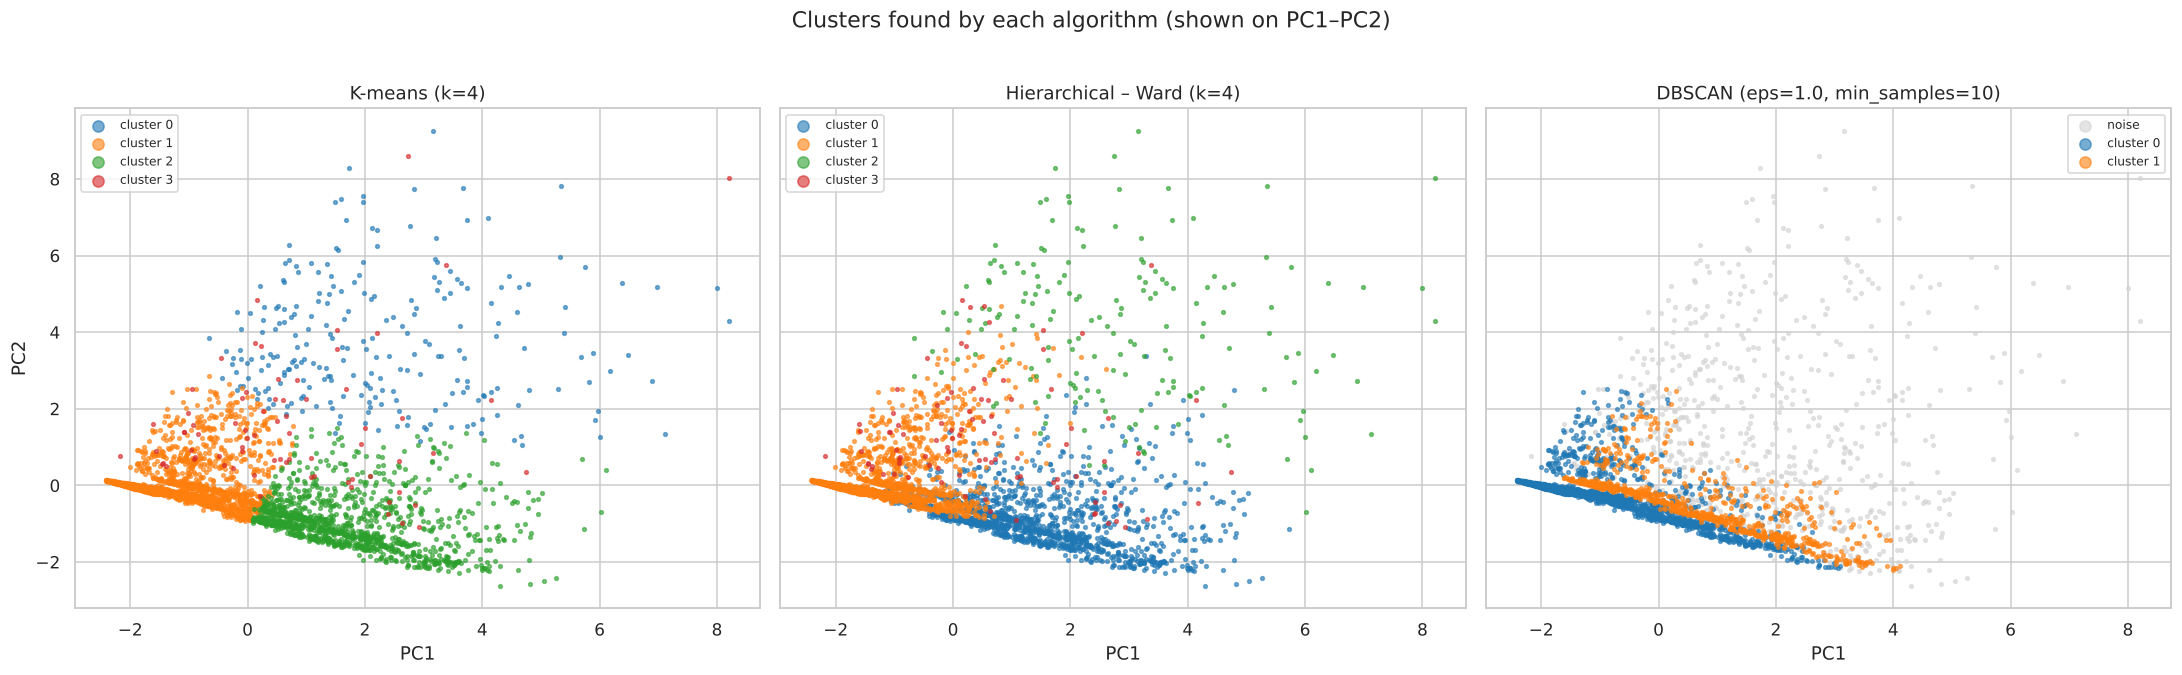

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)
titles = ["K-means (k=4)", "Hierarchical – Ward (k=4)", f"DBSCAN (eps={best.eps}, min_samples={int(best.min_samples)})"]
for ax, labels, title in zip(axes, [km_labels, hc_labels, db_labels], titles):
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=6, alpha=.6, color="lightgrey" if c == -1 else plt.cm.tab10(c), label="noise" if c == -1 else f"cluster {c}")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.legend(markerscale=3, fontsize=8)
axes[0].set_ylabel("PC2"); plt.suptitle("Clusters found by each algorithm (shown on PC1–PC2)", y=1.02); plt.tight_layout(); save("A_clusters_pca")

*Interpretation:* K-means and Ward give a very similar picture — the dense lower band is split into low-activity customers and card earners, and the spread-out upper area holds the frequent flyers and Topflight qualifiers. DBSCAN finds two bands and marks most of the upper area as noise (grey).

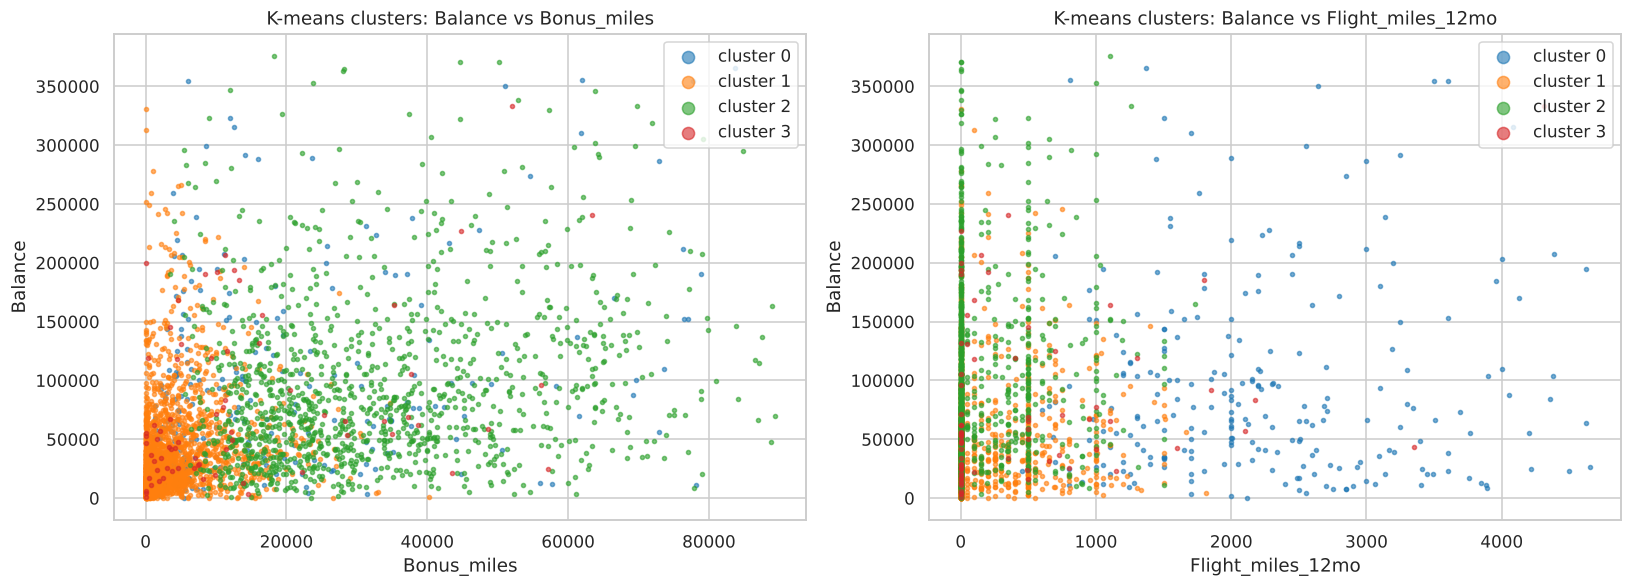

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (xc, yc) in zip(axes, [("Bonus_miles", "Balance"), ("Flight_miles_12mo", "Balance")]):
    for c in range(4):
        m = km_labels == c
        ax.scatter(air_clean.loc[m, xc], air_clean.loc[m, yc], s=7, alpha=.6, color=plt.cm.tab10(c), label=f"cluster {c}")
    ax.set_xlabel(xc); ax.set_ylabel(yc); ax.set_title(f"K-means clusters: {yc} vs {xc}"); ax.legend(markerscale=3)
plt.tight_layout(); save("A_kmeans_scatter")

*Interpretation:* in the original features the K-means clusters are clearly separated: card earners have high bonus miles but few flight miles, frequent flyers have high flight miles, and low-activity members have low values everywhere.

## A8. Cluster analysis and interpretation

In [24]:
def profile(labels):
    p = air_clean.assign(cluster=labels).groupby("cluster").mean()
    p.insert(0, "customers", pd.Series(labels).value_counts().sort_index())
    p.insert(1, "share_%", 100*p["customers"]/len(labels))
    return p
km_profile = profile(km_labels); display(km_profile.round(1))

,customers,share_%,Balance,Qual_miles,cc1_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
cluster,,,,,,,,,,,
0,241,6.600,"95,316.700",59.700,2.000,"19,772.200",16.300,"2,218.100",6.300,"4,301.300",0.600
1,2174,59.100,"37,150.000",3.100,1.100,"3,684.000",6.200,93.700,0.300,"3,662.200",0.200
2,1190,32.400,"95,176.600",6.100,3.500,"32,947.100",17.300,144.400,0.500,"4,730.000",0.600
3,72,2.000,"77,728.100","1,616.800",1.800,"14,244.100",10.800,468.700,1.500,"4,255.000",0.600


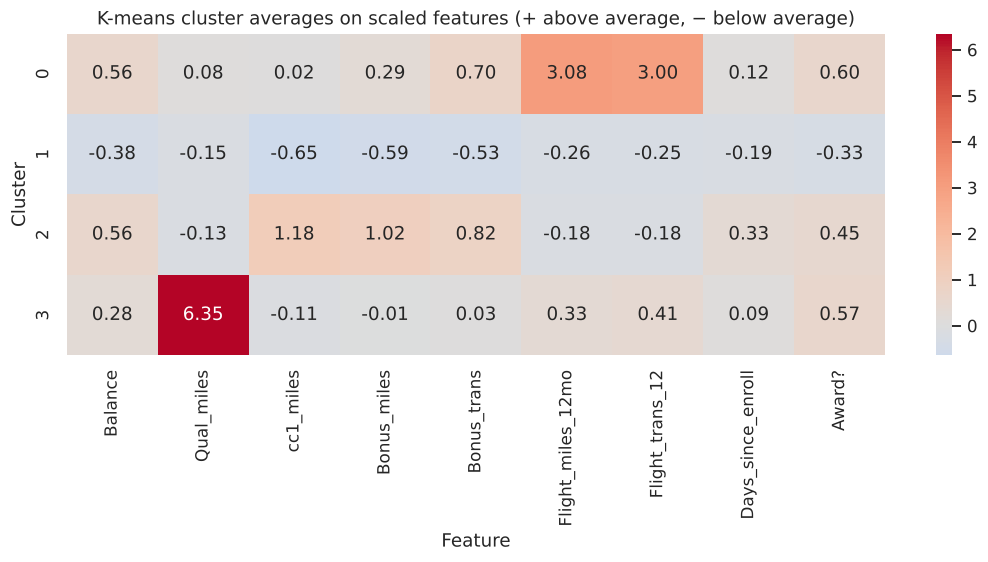

In [25]:
centres = pd.DataFrame(X, columns=features).assign(cluster=km_labels).groupby("cluster").mean()
plt.figure(figsize=(12, 3.8))
sns.heatmap(centres, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("K-means cluster averages on scaled features (+ above average, − below average)"); plt.xlabel("Feature"); plt.ylabel("Cluster"); save("A_kmeans_profile_heatmap")

*Interpretation:* red cells show features where a cluster is above the average customer and blue cells below. Each cluster has a clear pattern (for example, one cluster is high only on flight features, another only on Qual_miles), which makes the clusters easy to name.

In [26]:
# give each K-means cluster a name based on its average values
names = {}
for c, r in km_profile.iterrows():
    if r.Qual_miles > 500:          names[c] = "Topflight qualifiers"
    elif r.Flight_trans_12 > 3:     names[c] = "Frequent flyers"
    elif r.cc1_miles >= 3:          names[c] = "Credit-card earners"
    else:                           names[c] = "Low-activity members"
km_profile.insert(0, "segment", pd.Series(names))
display(km_profile[["segment", "customers", "share_%", "Balance", "cc1_miles", "Bonus_miles", "Flight_trans_12", "Qual_miles", "Days_since_enroll", "Award?"]].round(2))

,segment,customers,share_%,Balance,cc1_miles,Bonus_miles,Flight_trans_12,Qual_miles,Days_since_enroll,Award?
cluster,,,,,,,,,,
0,Frequent flyers,241,6.550,"95,316.700",2.020,"19,772.220",6.290,59.750,"4,301.320",0.620
1,Low-activity members,2174,59.120,"37,150.000",1.140,"3,683.990",0.340,3.140,"3,662.160",0.180
2,Credit-card earners,1190,32.360,"95,176.640",3.550,"32,947.060",0.460,6.090,"4,729.980",0.550
3,Topflight qualifiers,72,1.960,"77,728.080",1.850,"14,244.120",1.540,"1,616.850","4,255.040",0.610


### Insights — K-means segments (k = 4)

| Segment | Customers | Profile | Suggested action |
|---|---|---|---|
| **Low-activity members** | 2,174 (59.1%) | Lowest balance (~37,150), card bin ≈ 1, few bonus miles (~3,700), almost no flights, newest members, only 18% redeemed an award | Re-activation offers through low-cost channels (email/app) |
| **Credit-card earners** | 1,190 (32.4%) | High balance (~95,200) and the most bonus miles (~32,900) with the highest card bin (≈ 3.5), but hardly fly (0.46 flights); longest-enrolled; 55% redeemed | They collect miles but don't fly — offer fare deals and "use your miles" campaigns |
| **Frequent flyers** | 241 (6.6%) | ~6.3 flights and ~2,200 flight miles in 12 months, high balance (~95,300), 62% redeemed | Upgrade path to Topflight status, route promotions |
| **Topflight qualifiers** | 72 (2.0%) | The only group with qualifying miles (~1,600 on average); 61% redeemed | Most valuable — retain with status perks and priority service |

**Comments**
1. The customers separate along two behaviours: **earning miles through the credit card / bonuses** and **actually flying**.
2. About one third of customers earn many miles on the card but almost never fly — the biggest marketing opportunity.
3. More than half of the customers are low-activity; award redemption is lowest in this group (18%) and around 55–62% in the other three.

In [27]:
display(profile(hc_labels).round(1))
print("K-means vs Ward (rows = K-means segment, columns = Ward cluster):")
display(pd.crosstab(pd.Series(km_labels).map(names), pd.Series(hc_labels, name="ward")))
print("Rand score between K-means and Ward:", round(rand_score(km_labels, hc_labels), 3))

,customers,share_%,Balance,Qual_miles,cc1_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
cluster,,,,,,,,,,,
0,1385,37.700,"92,551.900",2.500,3.300,"29,421.000",16.300,139.100,0.400,"4,479.400",0.500
1,2023,55.000,"34,356.100",0.000,1.100,"3,254.000",5.900,142.200,0.500,"3,768.200",0.200
2,177,4.800,"102,519.300",78.100,2.300,"24,720.500",18.900,"2,402.500",7.100,"4,053.000",0.600
3,92,2.500,"73,472.300","1,386.700",1.900,"14,133.500",10.300,416.900,1.300,"4,227.000",0.600


K-means vs Ward (rows = K-means segment, columns = Ward cluster):


ward,0,1,2,3
row_0,,,,
Credit-card earners,1137,38,8,7
Frequent flyers,17,54,166,4
Low-activity members,231,1931,1,11
Topflight qualifiers,0,0,2,70


Rand score between K-means and Ward: 0.85


**Hierarchical (Ward) comments:** Ward finds almost the same four segments — card earners (1,385), low-activity (2,023), frequent flyers (177) and Topflight qualifiers (92). The cross-table shows strong agreement: 70 of the 72 K-means Topflight qualifiers and 1,137 of the 1,190 card earners are in matching Ward clusters. The main difference is that Ward places 231 of the K-means low-activity customers with the card earners. The **Rand score of 0.85** means the two methods put 85% of customer pairs the same way (together or apart), so the segments are stable across algorithms.

In [28]:
display(profile(db_labels).round(1))
print("K-means vs DBSCAN:")
display(pd.crosstab(pd.Series(km_labels).map(names), pd.Series(db_labels, name="dbscan")))

,customers,share_%,Balance,Qual_miles,cc1_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
cluster,,,,,,,,,,,
-1,727,19.800,"117,773.500",199.300,2.600,"26,222.500",16.500,"1,017.000",3.000,"4,612.100",0.600
0,2131,58.000,"46,145.200",0.000,1.600,"8,038.100",7.900,59.100,0.200,"3,736.500",0.000
1,819,22.300,"47,173.700",0.000,2.500,"20,529.500",12.100,95.800,0.300,"4,417.200",1.000


K-means vs DBSCAN:


dbscan,-1,0,1
row_0,,,
Credit-card earners,314,408,468
Frequent flyers,238,1,2
Low-activity members,103,1722,349
Topflight qualifiers,72,0,0


**DBSCAN comments:**
1. DBSCAN finds only **two clusters**, and they are split exactly by **`Award?`**: cluster 0 contains only customers who never redeemed an award, cluster 1 only customers who did. Because `Award?` is 0/1, it creates two dense "layers" of points.
2. About **20% of customers are marked as noise** — and these are the **most valuable customers**: all 72 Topflight qualifiers and 238 of the 241 frequent flyers. They are spread out (low density), so DBSCAN treats them as outliers.
3. DBSCAN is useful here for **detecting unusual (high-value) customers**, but not for building marketing segments, because the data has a dense crowd of low-activity customers and a sparse group of active ones.

## A9. Evaluation — comparing the three algorithms

,clusters,noise_%,silhouette,davies_bouldin
K-means,4,0.000,0.331,1.163
Hierarchical (Ward),4,0.000,0.288,1.251
DBSCAN (non-noise points),2,19.772,0.301,1.534


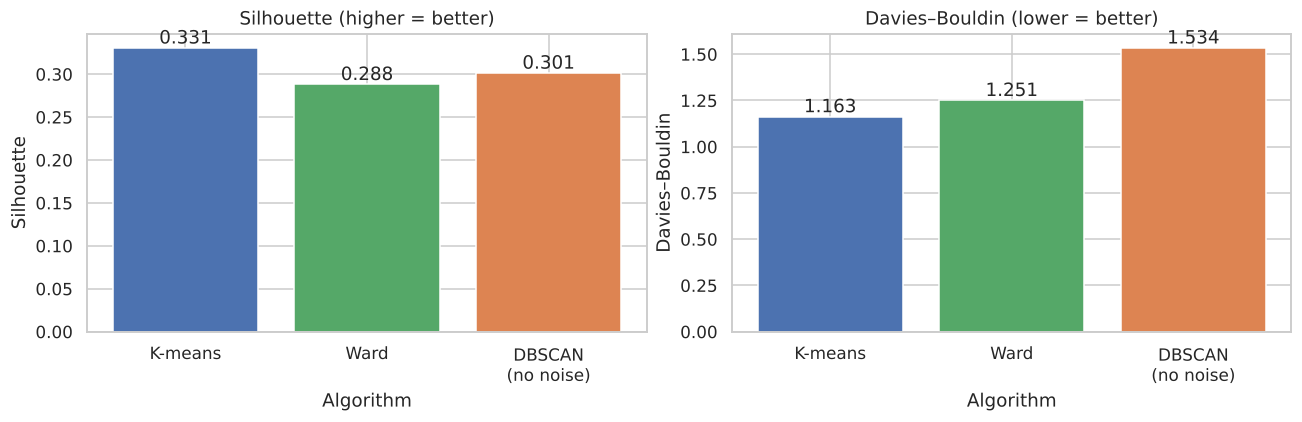

In [29]:
m = db_labels != -1
results = pd.DataFrame({
    "clusters": [4, 4, len(set(db_labels[m]))],
    "noise_%": [0, 0, 100*(~m).mean()],
    "silhouette": [silhouette_score(X, km_labels), silhouette_score(X, hc_labels), silhouette_score(X[m], db_labels[m])],
    "davies_bouldin": [davies_bouldin_score(X, km_labels), davies_bouldin_score(X, hc_labels), davies_bouldin_score(X[m], db_labels[m])],
}, index=["K-means", "Hierarchical (Ward)", "DBSCAN (non-noise points)"])
display(results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in zip(axes, ["silhouette", "davies_bouldin"], ["Silhouette (higher = better)", "Davies–Bouldin (lower = better)"]):
    ax.bar(["K-means", "Ward", "DBSCAN\n(no noise)"], results[col], color=["#4C72B0", "#55A868", "#DD8452"]); ax.set_title(title); ax.set_xlabel("Algorithm"); ax.set_ylabel(col.replace("_", "–").title())
    for i, v in enumerate(results[col]): ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.tight_layout(); save("A_algorithm_comparison")

| | K-means | Hierarchical (Ward) | DBSCAN |
|---|---|---|---|
| Silhouette (higher = better) | **0.331** | 0.288 | 0.301 (noise removed) |
| Davies–Bouldin (lower = better) | **1.163** | 1.251 | 1.534 |
| Needs number of clusters? | Yes (elbow / silhouette) | Yes (cut the dendrogram) | No (needs eps, min_samples) |
| Handles noise / outliers | No | No | Yes — labels them −1 |
| Result here | 4 clear segments | Same 4 segments | 2 groups split by Award? + 20% noise |

**Conclusion (Case Study 2):** K-means with k = 4 gives the best scores (highest silhouette, lowest Davies–Bouldin) and four easy-to-explain segments, and Ward hierarchical clustering confirms them (Rand score 0.85). A silhouette of about 0.33 means the clusters are reasonably but not perfectly separated, which is normal for real customer data. **K-means (k = 4) is recommended** for customer segmentation.

---
# Part B — Case Study 5: Wine Quality Analysis and Prediction (Regression)

**Problem:** the company currently relies on sensory (taster) quality assessments. Management wants to know whether **physicochemical laboratory measurements** can explain differences in wine quality and support a data-driven quality assessment.

**Dataset:** the zip file has red (1,599) and white (4,898) wine samples. Red and white wines have different chemistry, so they should not be mixed. This analysis uses the **red wine** data.

## B0. Load and check the data

In [30]:
wine = pd.read_csv("data/winequality-red.csv", sep=";")
print("Shape:", wine.shape)
display(wine.head())
print("Missing values:", wine.isnull().sum().sum())
print("Duplicate rows:", wine.duplicated().sum())
display(wine.describe().T)

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5


Missing values: 0
Duplicate rows: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,"1,599.000",8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,"1,599.000",0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,"1,599.000",0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,"1,599.000",2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,"1,599.000",0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,"1,599.000",15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,"1,599.000",46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,"1,599.000",0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,"1,599.000",3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,"1,599.000",0.658,0.170,0.330,0.550,0.620,0.730,2.000


*Observation:* 1,599 wines, 11 physicochemical attributes and the target `quality`. There are **no missing values**. There are **240 duplicate rows** — these are most likely the same wine tested and rated more than once, so they are kept (this is the usual practice for this dataset).

## Task 1 — Statistical analysis

### 1a. Mean, median, mode, standard deviation and skewness

In [31]:
cols = ["alcohol", "volatile acidity", "residual sugar"]
task1 = pd.DataFrame({
    "mean": wine[cols].mean(),
    "median": wine[cols].median(),
    "mode": wine[cols].mode().iloc[0],
    "std_dev": wine[cols].std(),
    "skewness": wine[cols].skew(),
})
display(task1.round(3))

,mean,median,mode,std_dev,skewness
alcohol,10.423,10.200,9.500,1.066,0.861
volatile acidity,0.528,0.520,0.600,0.179,0.672
residual sugar,2.539,2.200,2.000,1.410,4.541


*Observation:*
- **Alcohol:** mean 10.42 > median 10.20 > mode 9.5, skewness 0.86 → moderately **right-skewed**.
- **Volatile acidity:** mean 0.528 ≈ median 0.520, skewness 0.67 → slightly right-skewed.
- **Residual sugar:** mean 2.54 > median 2.20, skewness **4.54** → **highly right-skewed**; most red wines are dry (~2 g/dm³) with a few very sweet ones.

### 1b. Greatest relative variability — coefficient of variation (CV)

The three attributes have different units, so their standard deviations cannot be compared directly. **CV = standard deviation / mean** gives the spread as a percentage of the mean.

In [32]:
cv = (wine[cols].std() / wine[cols].mean() * 100).sort_values(ascending=False)
print("Coefficient of variation (%):"); print(cv.round(1))
print("\nGreatest relative variability:", cv.idxmax())

Coefficient of variation (%):
residual sugar     55.500
volatile acidity   33.900
alcohol            10.200
dtype: float64

Greatest relative variability: residual sugar


*Observation:* **residual sugar has the greatest relative variability (CV ≈ 55.5%)**, then volatile acidity (≈ 33.9%), while alcohol is the most stable (≈ 10.2%).

### 1c. Alcohol vs quality — Pearson correlation

Pearson r = 0.476   p-value = 2.83e-91


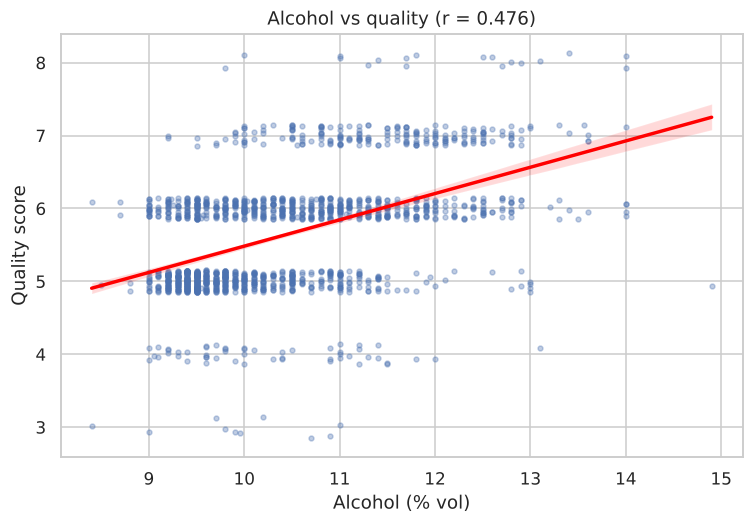

In [33]:
r, p = stats.pearsonr(wine["alcohol"], wine["quality"])
print(f"Pearson r = {r:.3f}   p-value = {p:.2e}")
plt.figure(figsize=(8, 5))
sns.regplot(x="alcohol", y="quality", data=wine, y_jitter=0.15, scatter_kws={"s": 10, "alpha": .35}, line_kws={"color": "red"})
plt.title(f"Alcohol vs quality (r = {r:.3f})"); plt.xlabel("Alcohol (% vol)"); plt.ylabel("Quality score"); save("B_alcohol_quality_scatter")

*Interpretation:* r = **+0.476** → the relationship is **positive** (higher alcohol → higher quality) and of **moderate strength** (|r| between 0.3 and 0.5). The p-value is far below 0.05, so the correlation is statistically significant. However, r² ≈ 0.23, so alcohol alone explains only about 23% of the variation in quality.

## Task 2 — Exploratory data analysis

### 2a. Histogram of quality scores

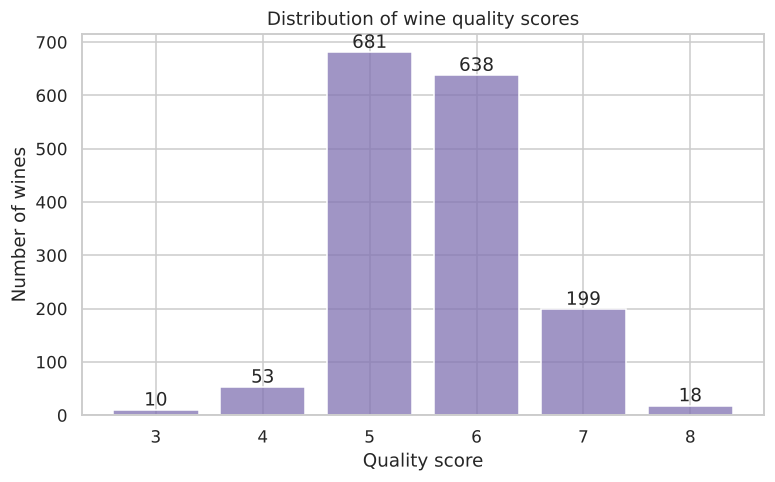

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [34]:
plt.figure(figsize=(8, 4.5))
ax = sns.histplot(wine["quality"], discrete=True, color="#8172B2", shrink=.8)
for bar in ax.patches:
    ax.annotate(int(bar.get_height()), (bar.get_x() + bar.get_width()/2, bar.get_height()), ha="center", va="bottom")
plt.title("Distribution of wine quality scores"); plt.xlabel("Quality score"); plt.ylabel("Number of wines"); save("B_quality_hist")
print(wine["quality"].value_counts().sort_index())

*Interpretation:* only scores 3–8 appear. Scores **5 and 6 make up about 82%** of all wines; very few wines are poor (3–4) or excellent (8). The distribution is roughly bell-shaped but **imbalanced**, so a model will have little data to learn the extreme scores.

### 2b. Box plot of alcohol grouped by quality

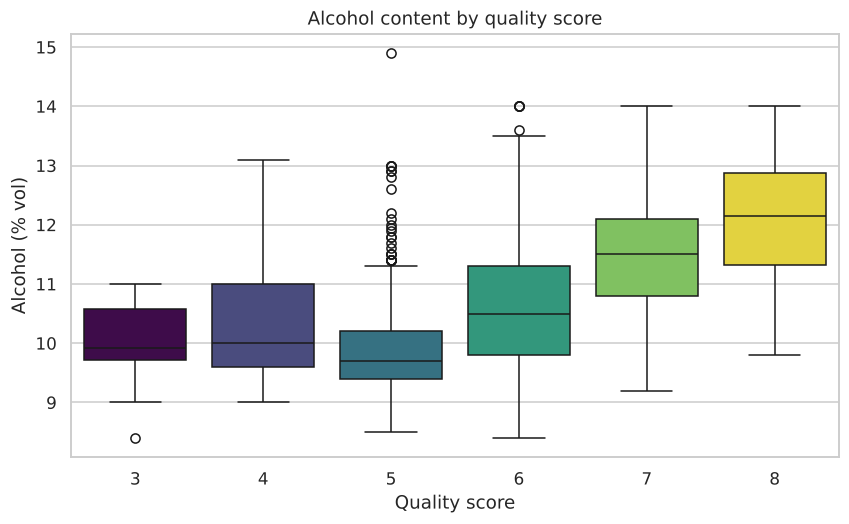

,count,median,mean,outliers
quality,,,,
3,10,9.930,9.960,1
4,53,10.000,10.270,0
5,681,9.700,9.900,30
6,638,10.500,10.630,5
7,199,11.500,11.470,0
8,18,12.150,12.090,0


In [35]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="quality", y="alcohol", data=wine, hue="quality", palette="viridis", legend=False)
plt.title("Alcohol content by quality score"); plt.xlabel("Quality score"); plt.ylabel("Alcohol (% vol)"); save("B_alcohol_box")

def count_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
display(wine.groupby("quality")["alcohol"].agg(count="count", median="median", mean="mean", outliers=count_outliers).round(2))

*Interpretation:*
- Median alcohol stays around **10%** for quality 3–5, then rises clearly: about 10.5% for 6, 11.5% for 7 and 12.15% for 8. Better wines contain more alcohol.
- **Outliers:** quality 5 has the most outliers (30) — wines with high alcohol (up to 14.9%) that still scored only 5. So high alcohol alone does not guarantee high quality.
- Quality 3 and 8 have very few wines (10 and 18), so their boxes are less reliable.

### 2c. Correlation heatmap

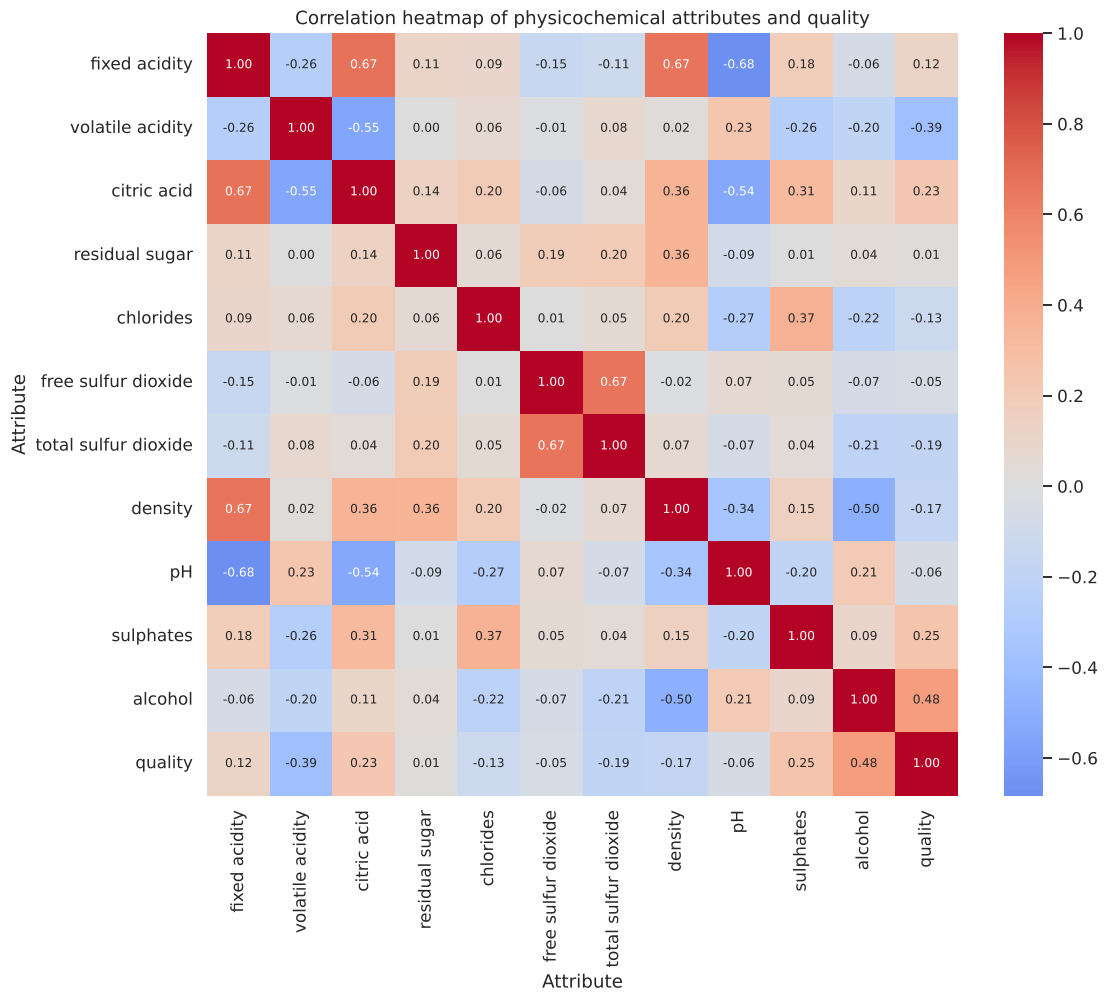

In [36]:
corr = wine.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation heatmap of physicochemical attributes and quality"); plt.xlabel("Attribute"); plt.ylabel("Attribute"); save("B_corr_heatmap")

*Observation:* some independent variables are strongly correlated with each other — fixed acidity with citric acid (+0.67), density (+0.67) and pH (−0.68), and free with total sulfur dioxide (+0.67). This is a sign of possible **multicollinearity** (checked in Task 3d).

### 2d. Two attributes most strongly associated with quality

,pearson_r,abs_r,direction
alcohol,0.476,0.476,positive
volatile acidity,-0.391,0.391,negative
sulphates,0.251,0.251,positive
citric acid,0.226,0.226,positive
total sulfur dioxide,-0.185,0.185,negative
density,-0.175,0.175,negative
chlorides,-0.129,0.129,negative
fixed acidity,0.124,0.124,positive
pH,-0.058,0.058,negative
free sulfur dioxide,-0.051,0.051,negative


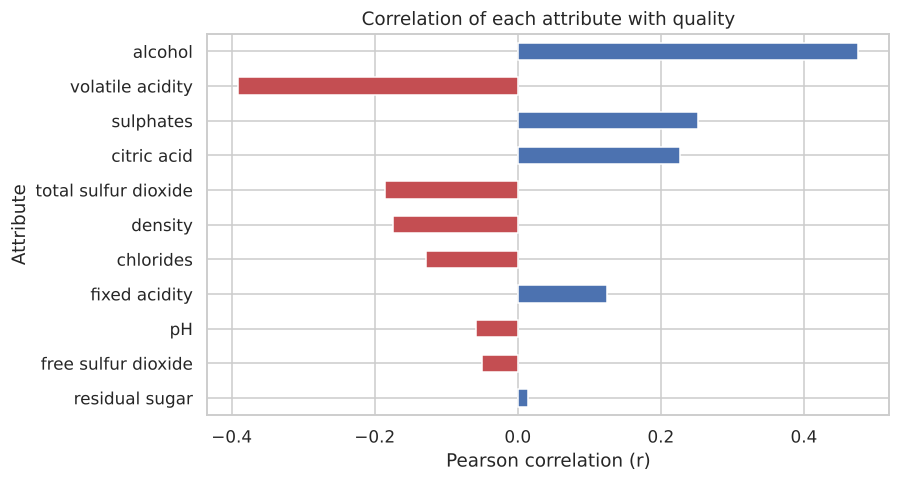

In [37]:
qcorr = corr["quality"].drop("quality")
ranked = qcorr.reindex(qcorr.abs().sort_values(ascending=False).index)
display(pd.DataFrame({"pearson_r": ranked, "abs_r": ranked.abs(), "direction": np.where(ranked > 0, "positive", "negative")}).round(3))
plt.figure(figsize=(8, 4.5))
ranked.plot.barh(color=["#C44E52" if v < 0 else "#4C72B0" for v in ranked]); plt.gca().invert_yaxis()
plt.title("Correlation of each attribute with quality"); plt.xlabel("Pearson correlation (r)"); plt.ylabel("Attribute"); save("B_corr_with_quality")

*Interpretation:*
1. **Alcohol (r = +0.476) — positive:** more alcohol is associated with higher quality.
2. **Volatile acidity (r = −0.391) — negative:** volatile acidity is mainly acetic acid; too much gives a vinegar taste, so more of it is associated with lower quality.

## Task 3 — Predictive modelling (multiple linear regression)

**Multiple linear regression:** quality = β₀ + β₁·x₁ + β₂·x₂ + … + β₁₁·x₁₁. Each β is the change in quality when that attribute increases by 1 unit and the others stay the same.

### 3a–3b. Train/test split (80/20) and model training

In [38]:
X_w = wine.drop(columns="quality")        # 11 independent variables
y_w = wine["quality"]                     # dependent (target) variable
X_train, X_test, y_train, y_test = train_test_split(X_w, y_w, test_size=0.2, random_state=RANDOM_STATE)
print("Training set:", X_train.shape, " Testing set:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)
print("Intercept (β0):", round(model.intercept_, 3))
display(pd.DataFrame({"coefficient": model.coef_}, index=X_w.columns).round(4))

Training set: (1279, 11)  Testing set: (320, 11)
Intercept (β0): 14.355


,coefficient
fixed acidity,0.023
volatile acidity,-1.001
citric acid,-0.141
residual sugar,0.007
chlorides,-1.806
free sulfur dioxide,0.006
total sulfur dioxide,-0.004
density,-10.352
pH,-0.394
sulphates,0.841


### 3c. Model evaluation on the test set

In [39]:
y_pred = model.predict(X_test)
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)
print(f"Mean Absolute Error (MAE)     : {mae:.3f}")
print(f"Mean Squared Error (MSE)      : {mse:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R-squared (R²)                : {r2:.3f}")

Mean Absolute Error (MAE)     : 0.504
Mean Squared Error (MSE)      : 0.390
Root Mean Squared Error (RMSE): 0.625
R-squared (R²)                : 0.403


*Interpretation:*
- **MAE ≈ 0.50** — on average the predicted score is half a point away from the actual score.
- **RMSE ≈ 0.62** — the typical prediction error is about 0.6 quality points.
- **R² ≈ 0.40** — the model explains about **40%** of the variation in wine quality; 60% is not explained by these 11 measurements. This is a moderate fit (R² close to 1 would be a near-perfect model).

### 3d. Most influential predictors — standardized coefficients and multicollinearity

The attributes have different units (density changes by ~0.002, sulfur dioxide by ~100), so the raw coefficients cannot be compared. We **standardize** the features (mean 0, std 1) and refit; each coefficient then means *change in quality for a 1-standard-deviation increase*, so they can be ranked.

**Multicollinearity** means independent variables are highly correlated with each other. It makes coefficients unstable and hard to interpret. It is detected with the **correlation matrix** (Task 2c) and the **Variance Inflation Factor (VIF)**: VIF = 1 → no multicollinearity, VIF > 5 → moderate, VIF > 10 → high.

,standardized_coef,abs_value,VIF
alcohol,0.297,0.297,2.933
volatile acidity,-0.179,0.179,1.813
sulphates,0.147,0.147,1.456
total sulfur dioxide,-0.120,0.120,2.203
chlorides,-0.089,0.089,1.520
pH,-0.061,0.061,3.275
free sulfur dioxide,0.058,0.058,1.983
fixed acidity,0.040,0.040,7.375
citric acid,-0.028,0.028,3.211
density,-0.019,0.019,6.016


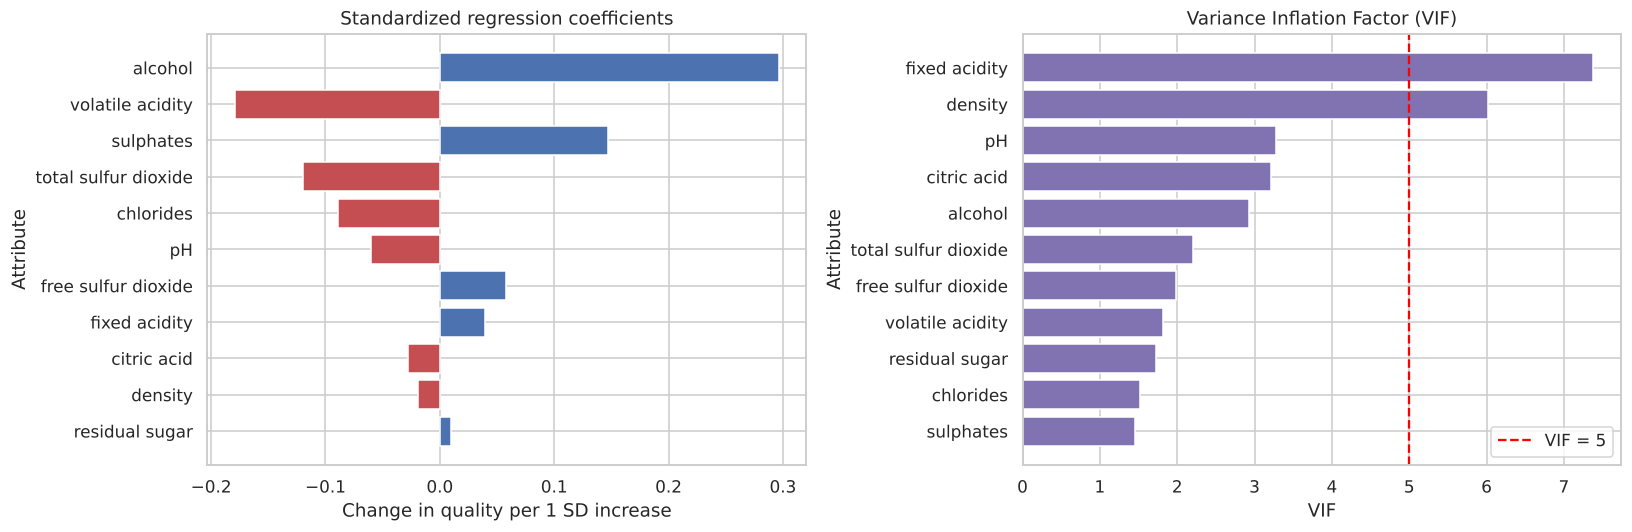

In [40]:
scaler = StandardScaler().fit(X_train)
std_model = LinearRegression().fit(scaler.transform(X_train), y_train)
std_coef = pd.Series(std_model.coef_, index=X_w.columns)

vif = pd.Series([variance_inflation_factor(np.column_stack([np.ones(len(X_train)), X_train.values]), i + 1)
                 for i in range(X_train.shape[1])], index=X_w.columns)
table3d = pd.DataFrame({"standardized_coef": std_coef, "abs_value": std_coef.abs(), "VIF": vif}).sort_values("abs_value", ascending=False)
display(table3d.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
s = table3d.standardized_coef
axes[0].barh(s.index, s.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in s]); axes[0].invert_yaxis(); axes[0].set_title("Standardized regression coefficients"); axes[0].set_xlabel("Change in quality per 1 SD increase"); axes[0].set_ylabel("Attribute")
v = table3d.VIF.sort_values(ascending=False)
axes[1].barh(v.index, v.values, color="#8172B2"); axes[1].invert_yaxis(); axes[1].axvline(5, color="red", ls="--", label="VIF = 5"); axes[1].legend(); axes[1].set_title("Variance Inflation Factor (VIF)"); axes[1].set_xlabel("VIF"); axes[1].set_ylabel("Attribute")
plt.tight_layout(); save("B_std_coef_vif")

*Multicollinearity check (before interpreting):*
- **Fixed acidity (VIF ≈ 7.4)** and **density (VIF ≈ 6.0)** have VIF > 5 → moderate multicollinearity. They are strongly correlated with citric acid, pH and alcohol, so their individual coefficients are unstable and should not be interpreted on their own. (Removing one of them would reduce this.)
- **Alcohol (VIF ≈ 2.9)** and **volatile acidity (VIF ≈ 1.8)** are below 5, so their coefficients can be trusted.

*Two most influential predictors:*
1. **Alcohol (+0.30):** a 1-standard-deviation increase in alcohol (~1.07%) raises predicted quality by about 0.30 points.
2. **Volatile acidity (−0.18):** a 1-standard-deviation increase (~0.18 g/dm³) lowers predicted quality by about 0.18 points.

This agrees with the correlation results in Task 2d.

### 3e. Predicted vs actual quality

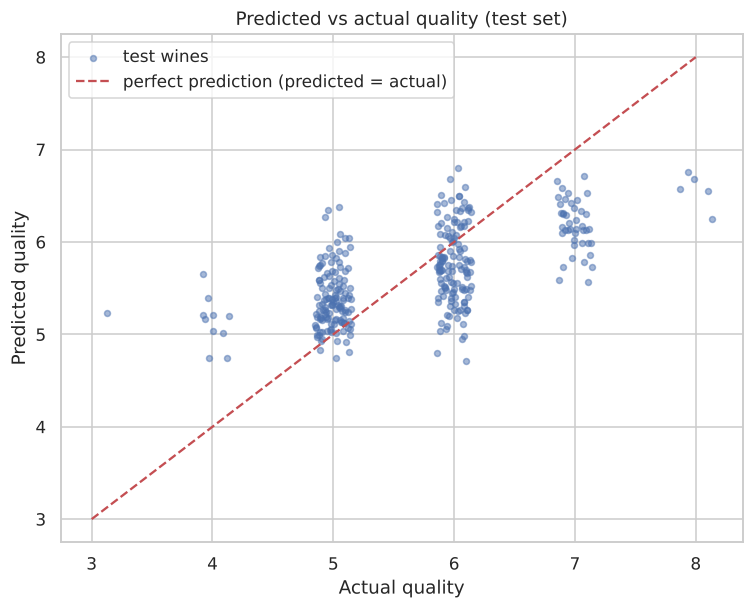

Range of predictions: 4.71 to 6.8


,count,mean
actual,,
3,1,5.230
4,10,5.140
5,130,5.380
6,132,5.760
7,42,6.180
8,5,6.560


In [41]:
plt.figure(figsize=(8, 6))
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.15, 0.15, len(y_test))
plt.scatter(y_test + jitter, y_pred, s=15, alpha=.5, label="test wines")
plt.plot([3, 8], [3, 8], "r--", label="perfect prediction (predicted = actual)")
plt.xlabel("Actual quality"); plt.ylabel("Predicted quality"); plt.title("Predicted vs actual quality (test set)"); plt.legend()
save("B_pred_vs_actual")
print("Range of predictions:", round(y_pred.min(), 2), "to", round(y_pred.max(), 2))
display(pd.DataFrame({"actual": y_test, "predicted": y_pred}).groupby("actual")["predicted"].agg(["count", "mean"]).round(2))

*Interpretation and limitations:*
1. The points do not lie on the red line. Predictions only range from about **4.7 to 6.8**, while actual scores go from 3 to 8.
2. The model **over-predicts poor wines** (actual 3–4 → predicted ≈ 5.2) and **under-predicts excellent wines** (actual 8 → predicted ≈ 6.6). It pulls every wine towards the average score of 5–6.
3. Quality is a whole number (3, 4, 5, …) but linear regression predicts decimals.
4. Very few training wines have quality 3, 4 or 8, so the model cannot learn them well.
5. The relationship is not perfectly linear (Task 2b: alcohol hardly changes between quality 3 and 5).

## Task 4 — Business decision-making

### 4a. Two measurements for laboratory quality screening
1. **Alcohol** — strongest positive correlation with quality (r = +0.476) and the largest standardized coefficient (+0.30), with low VIF. Useful for identifying **good** wines.
2. **Volatile acidity** — strongest negative correlation (r = −0.391) and second-largest coefficient (−0.18), with a low VIF of 1.8 (it carries independent information). Useful for flagging **poor / faulty** wines (vinegar taste).

### 4b. Can the regression model replace sensory evaluation? — **No**
- **R² ≈ 0.40:** 60% of the variation in quality is not explained by the lab measurements.
- **MAE ≈ 0.50 and RMSE ≈ 0.62:** an error of about half a point is the same as the difference between an "average" (5) and a "good" (6) wine — and 82% of wines are exactly 5 or 6.
- The model squeezes the extremes: poor wines are predicted as average, so faulty wines could pass.

**Recommendation:** use the model and the two measurements as a **first screening step** (for example, send wines with high volatile acidity or a low predicted score for tasting first), but keep sensory evaluation for the final decision.

### 4c. Limitations
1. **Dataset:** quality is a subjective taster score; only one type of wine (Portuguese red *vinho verde*); no information on grape variety, age or price; scores are imbalanced (most are 5 or 6) and there are 240 duplicate rows.
2. **Approach:** linear regression assumes straight-line relationships and treats a whole-number score as continuous; some predictors are correlated (fixed acidity, density, citric acid, pH), which makes their coefficients unstable; results come from a single 80/20 split.